In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize
import scipy.odr as odr

# Aufgabe 1

   Bestimmen Sie die Eigenfrequenz des Drehpendels für die freie (näherungsweise ungedämpfte) Schwingung
a) mit Hilfe einer Stoppuhr
b) aus der aufgenommenen Messkurve am Computer

#### Notwendige Formel:
$$
\omega = 2\pi f ,\quad T = \frac{1}{f} \quad \Rightarrow \omega_0 = \frac{2 \pi}{T}
$$

#### Übersicht a)
Gemessen wurde Zeit und Anzahl der Periode. Einzelmessung.
- Unsicherheit in Ablesegenauigkeit -> $\frac{0.01}{2\sqrt{3}}$
- Unsicherheit von der Reaktionszeit des Menschens -> $u_{Reaktion}$ 0.3 sek
- Unsicherheit durch das Gerät welches die Daten auf den PC überträgt

#### Übersicht b)
Gemessen wurde Zeit und der jeweilige Winkel der Auslenkung.
- Unsicherheit in Ablesegenauigkeit der Zeit -> $\frac{0.01}{2\sqrt{3}}$
- Unsicherheit in Ablesegenauigkeit der Kreisfrequenz -> $\frac{0.001}{2\sqrt{3}}$

### Vorgehen für a)
- Zeit der Gesamtenschwingung / Anzahl der Gesamtenschwingungen = Periodendauer
$$
\frac{T_7}{7} = T
$$
- Formel von oben anwenden

#### Unsicherheiten
Unsicherheit für die Periode. $T_7$ besteht aus zwei Größen, die unsicherheitsbelastet sind:
$$
u_{T_7} = \sqrt{u_{ablese}^2 + u_{Reaktion}^2} = \sqrt{ \left( \frac{0.01}{2\sqrt{3}} \right)^2 + (0.3)^2} = 0.3
$$

Fehlerfortpflanzung ?!
$$
u_T = \frac{u_{T_7}}{7} = 0.04
$$

Unsicherheit für die Eigenfrequenz $\omega_0$:
$$
u_{\omega_0} = \frac{2 \pi}{T^2} \cdot u_T 
$$

### Vorgehen für b)
- Daten einlesen 
- Fit für die Daten erstellen mit der Fkt.: $A \sin(\omega t + \varphi) + C$ 
- dieser Fit wird dann durch seine Fit-Parameter den besten Wert für $\omega$ ausgeben
- fertig i guess

#### Unsicherheiten
- die eingegebenen Daten sind durch Zweifaktoren mit unsicherheiten belastet. Einmal Ablesegenauigkeit und die Unsicherheit durch die Übertragung vom Sensor. Der Sensor macht 4000 Erkennungen pro Umdrehung. Umdrehun hier als Periode zu verstehen ?! Dann besitzt der Sensor eine Genauigkeit von 
$$ u_{Gerät} = \frac{4000}{Umdrehung} $$ 
Der Sensor hat eine maximale Drehrate von 
$$
f_{max} = 30 Umdrehung \frac{1}{s}
$$
Im schlimmsten Fall registriert der Sensor also \frac{400}{3} pro Sekunde. 
- werden mit dem Fit ausgegeben

- abgelesener Wert vom PC reicht scheinbar aus lol  

In [4]:
infile = open("V2und3.csv")
data = infile.read()
infile.close()
type(data)
new_data = data.replace(",", ".")
outfile = open("V2und3.csv", "w")
outfile.write(new_data)
outfile.close()

In [11]:
%matplotlib inline
time_0, angle_0 = np.loadtxt("V2und3.csv", 'float', skiprows= 1, unpack=True, usecols=(0,1), delimiter=';', max_rows = 143) 
time_0
#plt.scatter(time_0, angle_0)

array([0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 , 0.55,
       0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  , 1.05, 1.1 ,
       1.15, 1.2 , 1.25, 1.3 , 1.35, 1.4 , 1.45, 1.5 , 1.55, 1.6 , 1.65,
       1.7 , 1.75, 1.8 , 1.85, 1.9 , 1.95, 2.  , 2.05, 2.1 , 2.15, 2.2 ,
       2.25, 2.3 , 2.35, 2.4 , 2.45, 2.5 , 2.55, 2.6 , 2.65, 2.7 , 2.75,
       2.8 , 2.85, 2.9 , 2.95, 3.  , 3.05, 3.1 , 3.15, 3.2 , 3.25, 3.3 ,
       3.35, 3.4 , 3.45, 3.5 , 3.55, 3.6 , 3.65, 3.7 , 3.75, 3.8 , 3.85,
       3.9 , 3.95, 4.  , 4.05, 4.1 , 4.15, 4.2 , 4.25, 4.3 , 4.35, 4.4 ,
       4.45, 4.5 , 4.55, 4.6 , 4.65, 4.7 , 4.75, 4.8 , 4.85, 4.9 , 4.95,
       5.  , 5.05, 5.1 , 5.15, 5.2 , 5.25, 5.3 , 5.35, 5.4 , 5.45, 5.5 ,
       5.55, 5.6 , 5.65, 5.7 , 5.75, 5.8 , 5.85, 5.9 , 5.95, 6.  , 6.05,
       6.1 , 6.15, 6.2 , 6.25, 6.3 , 6.35, 6.4 , 6.45, 6.5 , 6.55, 6.6 ,
       6.65, 6.7 , 6.75, 6.8 , 6.85, 6.9 , 6.95, 7.  , 7.05, 7.1 , 7.15])

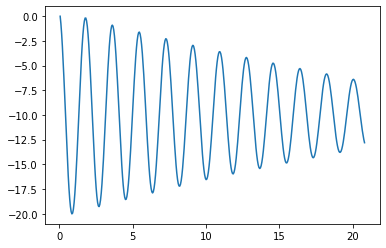

In [6]:
time_1, angle_1 = np.loadtxt("V2und3.csv", 'float', skiprows= 1, unpack=True, usecols=(2,3), delimiter=';', max_rows = 417) 
plt.plot(time_1, angle_1)

# Aufgabe 2
Bei drei verschiedene Dämpfungen durch die Wirbelstrombremse, Eigenfrequenz und Dämpfung bestimmen.

#### Notwendige Formeln:
Für den Fit ?!
$$
\varphi(t) = \varphi_0 e^{-\rho t}\cos(\sqrt{\omega_0^2 -\rho^2} \cdot t)
$$

#### Übersicht:
- 

In [7]:
def sinus_dam(t, A, rho, w):
    #A, rho, w = p
    angle = A*np.exp((-1)*rho*t)*np.cos(np.sqrt(w**2 - rho**2)*t)
    return angle

[-10.4979607    0.11955041   3.46189411]
2.1061512462836354 0.036027935573401115 0.036027935573401115


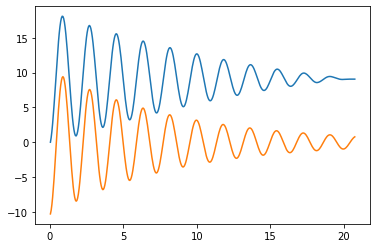

In [8]:
# Dämpfung mit I = 0.3
time_2, angle_2 = np.loadtxt("V2und3.csv", 'float', skiprows= 1, unpack=True, usecols=(4,5), delimiter=';', max_rows = 415) 
plt.plot(time_2, angle_2)

"""
mymodel = odr.Model(sinus_dam)

mydata = odr.RealData(time_2, angle_2)

myodr = odr.ODR(mydata, mymodel, beta0=[15.0, 0.1, 4.3])

myoutput = myodr.run()

myoutput.pprint()
"""

opt_2, cov_2 = optimize.curve_fit(sinus_dam, time_2, angle_2, p0=[8, 0.1, 3.4] )
A_2_opt, rho_2_opt, w_2_opt = opt_2
u_A_2, u_rho_2, u_w_2 = np.sqrt(np.diag(cov_2))
print(opt_2)
print(u_A_2, u_rho_2, u_rho_2)

plt.plot(time_2, sinus_dam(time_2, A_2_opt, rho_2_opt, w_2_opt))

[-6.8253718   0.19371249  3.55666822]
1.9426578739072164 0.08803798577150472 0.08803798577150472


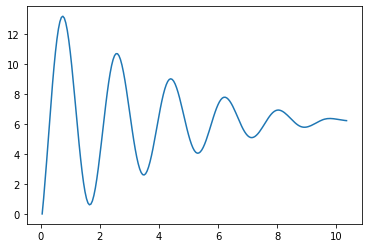

In [9]:
# Dämpfung mit I = 0.6
time_3, angle_3 = np.loadtxt("V2und3.csv", 'float', skiprows= 1, unpack=True, usecols=(6,7), delimiter=';', max_rows = 207) 
plt.plot(time_3, angle_3)

opt_3, cov_3 = optimize.curve_fit(sinus_dam, time_3, angle_3, p0=[-6, 0.2, 3.4] )
A_opt_3, rho_opt_3, w_opt_3 = opt_3
u_A_3, u_rho_3, u_w_3 = np.sqrt(np.diag(cov_3))
print(opt_3)
print(u_A_3, u_rho_3, u_rho_3)

[-6.60311159  0.41976912  3.38811698]
2.95936674928509 0.2749437466390465 0.2749437466390465


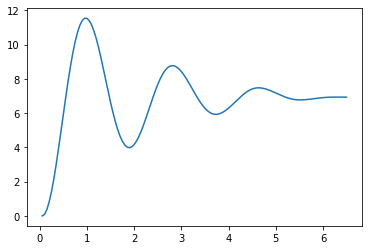

In [10]:
# Dämpfung mit I = 0.9
time_4, angle_4 = np.loadtxt("V2und3.csv", 'float', skiprows= 1, unpack=True, usecols=(8,9), delimiter=';', max_rows = 130) 
plt.plot(time_4, angle_4)

opt_4, cov_4 = optimize.curve_fit(sinus_dam, time_4, angle_4, p0=[-6, 0.2, 3.4] )
A_opt_4, rho_opt_4, w_opt_4 = opt_4
u_A_4, u_rho_4, u_w_4 = np.sqrt(np.diag(cov_4))
print(opt_4)
print(u_A_4, u_rho_4, u_rho_4)